# Chapter 2: Overview of Supervised Learning

A Python/Jupyter recreation of the Chapter 2 figures from *The Elements of
Statistical Learning* and the original R Markdown analysis in this repository.

The archived `ElemStatLearn::mixture.example` training sample and mixture
centers are embedded below, so the notebook runs without R or network access.
The random simulations use explicit NumPy generators for reproducibility.

**Dependencies:** NumPy, Matplotlib, SciPy, and scikit-learn.


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle
from scipy.special import logsumexp
from sklearn.linear_model import LinearRegression
from sklearn.metrics import pairwise_distances
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

BLUE, ORANGE, GREEN, RED = "deepskyblue", "orange", "mediumaquamarine", "tomato"
BG_CMAP = ListedColormap(["#cceeff", "#ffe1ae"])

def finish(ax, title, xlabel="x1", ylabel="x2"):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.set_aspect("equal", adjustable="box")

def classification_plot(model, X, y, title, resolution=180, boundary=None):
    pad = 0.15
    x1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, resolution)
    x2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, resolution)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], cmap=BG_CMAP, alpha=.75)
    if boundary is None:
        ax.contour(xx, yy, zz, levels=[.5], colors="black", linewidths=1)
    else:
        ax.contour(xx, yy, boundary(grid).reshape(xx.shape), levels=[.5],
                   colors="black", linewidths=1.2)
    for label, color in [(0, BLUE), (1, ORANGE)]:
        points = X[y == label]
        ax.scatter(points[:, 0], points[:, 1], facecolors="none",
                   edgecolors=color, linewidths=1.5, s=38)
    finish(ax, title)
    plt.show()


## Mixture example data

There are 100 observations from each class. Each class is an equal mixture of
ten spherical Gaussian components; the first ten centers belong to class 0 and
the remaining ten to class 1. These are the original package values.


In [2]:
X_train = np.array([[2.5260929678784914, 0.3210504457363648], [0.3669544719769291, 0.03146209878542522], [0.7682190762983832, 0.7174861663560391], [0.6934356804018488, 0.7771940337983256], [-0.0198366163257222, 0.8672537379765065], [2.196544934562817, -1.023014057752322], [-0.10915915714124866, -0.5306210800307046], [-0.9126200585129358, 1.2162163810147482], [2.4998426506446765, -0.41827789787031655], [1.8977091071491425, 0.9737554977697039], [-0.295362353136713, 0.009673167708244779], [-0.6815957356081886, -0.551650278237261], [2.490978712962284, 1.148315275050769], [-0.053430597123768575, 0.4841024604854972], [0.6876175919845051, 0.7050048180366882], [1.2795595230267325, -0.2710332900576715], [-0.3130074767141546, 1.2737473147004459], [2.8130386082809586, 1.1677597134373956], [0.3199881458618468, 0.01720164860058812], [0.4375423763366304, 0.413648012486852], [2.4329393597864146, -1.3143631336392043], [-0.42964958497032485, -0.30981121895658437], [0.24872840099202165, 0.8555198791038445], [2.693936802424537, -1.9998534020399017], [1.4671092457064865, 1.8775907185830643], [1.0406973415596967, -0.08518756914839859], [0.03331846285714296, 1.9302574927239347], [1.7256814293223255, -0.45595914191320885], [1.1494807082978171, -0.9197902861665654], [2.12686851627158, 1.1541799963968113], [2.9881264899718416, 0.6723506642300492], [1.0718660571529002, -1.6430184228882174], [1.0848273011463605, 0.10297532419826155], [0.26744225179946757, 0.36282637769343606], [1.2828789405224326, 1.2769012468054879], [0.12998561891819072, 0.5441776947197929], [2.489806031342451, 1.358509887935134], [0.8184299906381222, 0.37900041894573644], [1.5322579221726909, -1.082164289941998], [0.7085429157159093, 0.022464060865776334], [1.5209142898070178, -0.7428514857964974], [0.8875587939568188, 0.8835521734684479], [1.5769765079797022, -0.7449336028231051], [2.3427655103989355, 0.35847776944136023], [-0.19127236424288627, 2.4936857027186083], [1.7491880143184486, -0.35791592811844464], [-0.8403690505309602, 1.881741308473241], [0.9461838586508129, 0.07329360494095538], [0.9152772357229205, -0.9017593509294711], [1.3487005464958384, 0.07045255344983159], [2.9298637258501907, 0.7388925157995486], [0.3232066126008334, 0.2879592427337803], [2.071415037514197, -0.8304147600900884], [-0.3022746640283053, 0.8862326091975481], [0.19228252475824997, -0.47944654621188504], [-0.727077154624771, 1.457361044001308], [0.13434746881871495, 0.9016757870174037], [-0.07711446064542532, 0.505121684500503], [2.7107635582811738, 0.8766447951491123], [4.170746207536664, 1.0798337666833908], [0.325768984205956, 0.3479957975320627], [0.20519012850165402, 2.453887785122332], [1.6401574882435543, 1.6085369491040065], [-0.07958335272853989, 0.3233119785090031], [2.742092421779995, -1.6003527691547892], [0.3107850388813922, 2.0079817366823782], [2.2900423762611304, 0.13738974796326736], [0.6599062269401198, -1.2416367017070686], [0.5164290774312524, 0.5251515578457288], [2.4829420282273906, -0.73717646428736], [1.0531887837775886, -0.9035655938257396], [1.7152333314440895, -1.0147268220197208], [1.2106244985526613, -0.10915038664253673], [1.0720359456981945, -0.16520464947456087], [0.8787065877870582, -0.7871349232879916], [0.951265099393954, -1.0958897672211638], [0.4254756825847046, 0.18489861652098358], [2.1251047903587317, -0.7618471439713862], [0.08761478650725063, -0.7333474121154041], [2.285264979847498, 1.0089930392447148], [0.470808789990068, 0.025438551375028567], [3.6115746686569983, 0.4905360182980869], [2.576843426146333, -1.4356821323602216], [1.816825183442743, -1.1617427889429466], [2.892025340123266, 1.6257830442134504], [0.9168229864216305, -0.4819207594437852], [-0.07407910137926044, 0.919702238001636], [0.574290652373292, -0.4546574094288818], [-0.5890458431983868, 0.2073235509624145], [2.624577967830412, -1.406259449595697], [0.06633219170536875, 1.5808054453632159], [1.6428446490667639, -0.2838785591047549], [2.5514461535268946, 1.4181804124056394], [1.4195370213472636, -0.029746130214851618], [-0.7152838353849232, 1.1078835533795415], [0.43450130004193266, -0.06454530203434927], [2.3437305938487105, 0.9109784736986708], [2.262714147735147, 0.6936015744653018], [0.9538334792220717, 0.3260342937483125], [1.2971673104088421, -1.1135411696682094], [1.8708997454336374, 0.654564442707802], [3.6378630232126707, 1.0391674430182114], [3.5292641990586513, 0.9599905642248133], [-0.20068316132799455, 2.2815850464238876], [1.0769569742209977, -0.3307352318152099], [-0.4007617226321328, 0.5858438876308283], [-0.36877579336734084, 1.0389226996422458], [1.6132127098558868, 1.8600809513957528], [1.3012024248401555, 0.7257996029961222], [1.2387699950931046, 1.0522357075760846], [1.4860048007980515, 1.714859662947238], [1.098734772552498, 0.9619480087455063], [0.6922200333154178, 2.2552675065997567], [1.079757234591018, 0.7422679527643732], [-2.0733187325684463, 1.7354237740481877], [-2.017570738404631, 2.720376775470377], [1.3511035907686106, 0.6497055782041571], [0.5286980933895282, 1.647575574214494], [1.741742103693826, 1.357381622732881], [0.752532941165452, 0.8090501524123588], [-0.15282240852521248, 2.4331157476426104], [-1.2648608172963804, 1.384068805275544], [1.3344109882606836, -0.2944409568816577], [1.2240541615084843, 0.47074712504101457], [-1.4646908530242717, 2.473922168985237], [1.623801764902402, 0.2409369395122592], [-2.169201473003773, 2.075904398399914], [0.4887465023590983, 2.142041681453649], [-1.1365390739500567, 2.0526862027216604], [-2.3038627621875847, 2.2074889348951205], [-0.0195930154288912, 1.8052993798675467], [-1.529105571855813, 2.6645283114134846], [-0.07129517043019758, 1.460543432890803], [0.8802308650399548, 1.2428694282414001], [0.013973130315264648, 1.2831859426272159], [0.43358288536953693, 1.261365481405923], [1.269316908677128, 1.6330625781131745], [1.4321360100517206, 0.3064750765311234], [-0.167523861886515, 2.7751924713772724], [-0.07197436755981457, 1.427912818767849], [-0.3116479815091121, 2.0410985160534847], [2.228716378882246, 0.9362233115565366], [-1.7769260873678312, 2.1088048621673257], [1.0474575855363717, 1.039996186931286], [-0.8042938554239449, 1.1356684489940547], [1.0583485649334616, 1.4898296025536932], [0.061145537068732714, 0.8014227083715182], [0.12502139270112744, 1.165593850760057], [-2.4774176167150244, 1.0265062045008033], [1.4424425536598657, 1.5454766925251575], [1.0284642888463151, 1.55098557929079], [-0.5823566842232073, 1.7188853975601086], [-1.9607797127875009, 2.0022742420391064], [2.8879470277189387, 0.020693004335722964], [1.391351682211968, 0.8137217227806057], [-1.796286610143445, 0.7717314859199809], [3.1669715507107234, 0.5569466267218904], [-0.4872926511592589, 0.9791104953053051], [0.5081180672644526, 1.7572319896677935], [1.591324821646979, 0.2152116339530477], [1.385771563581421, 1.2012217036258361], [0.5668173108032332, -0.16610305103937423], [-0.37030959001169583, 2.8558049669193197], [1.92657181412423, 0.1508643525570611], [-0.570429501077657, 1.0903140314972943], [3.5031264602195447, 1.2239818522616708], [1.5108276886319414, 2.4778652855152403], [-0.3694933477466136, 1.3846001800421612], [1.5223103746569846, 0.1861561369731194], [0.05618443072596709, 2.519258089043157], [0.571872338312731, 1.5779421778016531], [0.005244683456819027, 2.1256072345815014], [1.1266448057376794, 0.6659123970182377], [1.9454294402109547, 0.4810804986572634], [1.2444384420447803, 0.8523226872619081], [-0.4144416642112341, 1.0581471782890777], [-0.2571362795101113, 1.0851839085632733], [1.2874218471109593, 0.2725847621136956], [1.4362780771672303, 1.1747712811199977], [-1.256441709421901, 2.181549766518036], [1.2702896016437286, 1.7041398103014338], [0.2588807576657943, 1.1700552701008207], [1.5182939552985941, 0.36173417241909156], [0.8406974509100436, 1.5654750210598918], [-0.26475667573582, 1.4918324255196902], [-0.6684454800648606, 1.1039144412647757], [1.4862477060446035, 0.9181804754170582], [0.2594335655945349, 1.250357925112327], [3.5606129832319744, 1.3989888416021112], [-1.1627630704700294, 1.2509707889679518], [-1.0217841276173116, 2.4219165114302936], [-1.1692586053264682, 0.8129676186994921], [0.2054561209812682, 2.6885575509133006], [-2.5208196765959814, 2.0150332485632734], [0.45534177890494465, 0.4040379720427978], [0.2567502216082692, 2.2936045750251957], [1.9251733841286611, 0.1650526387706841], [1.301941034529533, 0.9921996155219414], [0.008130555950023488, 2.242263909769238], [-0.19624633408740333, 0.5514035592978709]])
y_train = np.r_[np.zeros(100, dtype=int), np.ones(100, dtype=int)]
mixture_means = np.array([[-0.2534331586535965, 1.741478798763345], [0.2666931784302785, 0.3712341020785001], [2.0964692117434867, 1.2333641725778826], [-0.06127272050452337, -0.2086791325079046], [2.703540851326801, 0.5968283235061154], [2.377211982197873, -1.1864147038492276], [1.0569075944022723, -0.6838939375174591], [0.5788835395009968, -0.06834580177840684], [0.624252127188094, 0.5987383900862856], [1.6733549531639544, -0.2893159217221188], [1.1993686923406663, 0.24840855475368195], [-0.30256109507075757, 0.9454189585972025], [0.05727232057316437, 2.4197271457478964], [1.3293220302477249, 0.819225984741309], [-0.07938424052127376, 1.61380166597827], [3.5079267267261245, 1.052986297438916], [1.6139228994925994, 0.6717378253114348], [1.0075357023160694, 1.3683071230542907], [-0.454621406426687, 1.0860697297724693], [-1.7980180475775427, 1.92978056103932]])

print(f"training predictors: {X_train.shape}")
print(f"class counts: {np.bincount(y_train)}")


training predictors: (200, 2)
class counts: [100 100]


## Figure 2-1 — Classification using linear regression

Least squares treats the binary labels as numeric. Thresholding predictions at
0.5 produces a straight decision boundary.


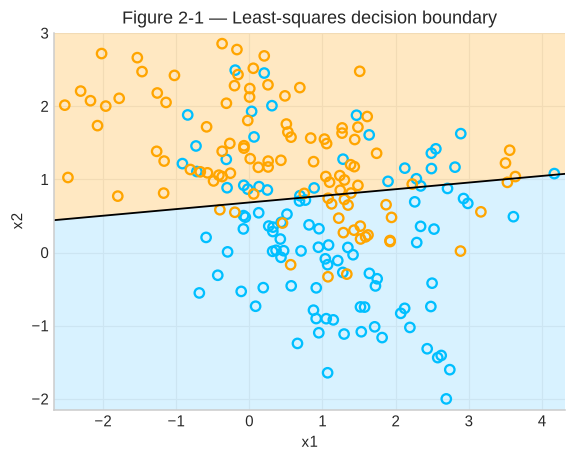

intercept and coefficients: [ 0.3291 -0.0226  0.2496]


In [3]:
linear_classifier = LinearRegression().fit(X_train, y_train)
classification_plot(
    linear_classifier, X_train, y_train,
    "Figure 2-1 — Least-squares decision boundary",
    boundary=lambda points: linear_classifier.predict(points),
)
print("intercept and coefficients:",
      np.r_[linear_classifier.intercept_, linear_classifier.coef_].round(4))


## Figure 2-2 — Classification using 15-nearest-neighbors

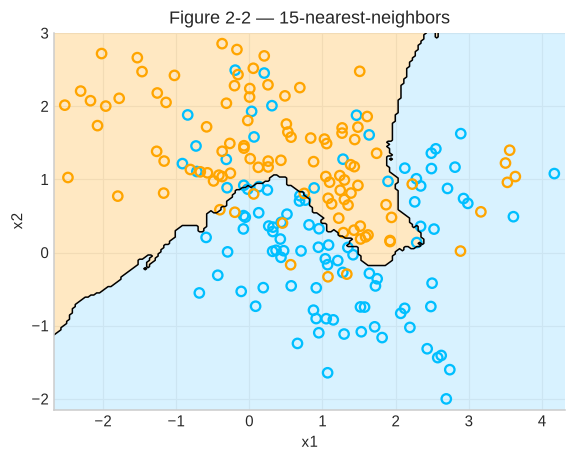

In [4]:
knn15 = KNeighborsClassifier(n_neighbors=15).fit(X_train, y_train)
classification_plot(knn15, X_train, y_train,
                    "Figure 2-2 — 15-nearest-neighbors")


## Figure 2-3 — Classification using 1-nearest-neighbor

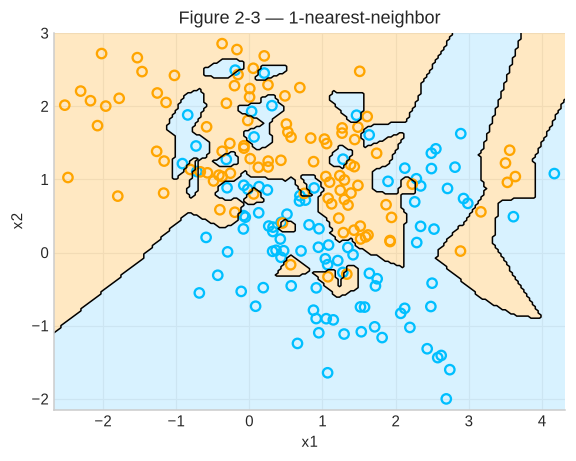

In [5]:
knn1 = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
classification_plot(knn1, X_train, y_train,
                    "Figure 2-3 — 1-nearest-neighbor")


## Figure 2-4 — Training and test error for nearest-neighbors

The independent test sample follows the data-generating process described in
the book: choose one of the ten class-specific centers uniformly, then add
bivariate Gaussian noise with covariance $0.2 I$.


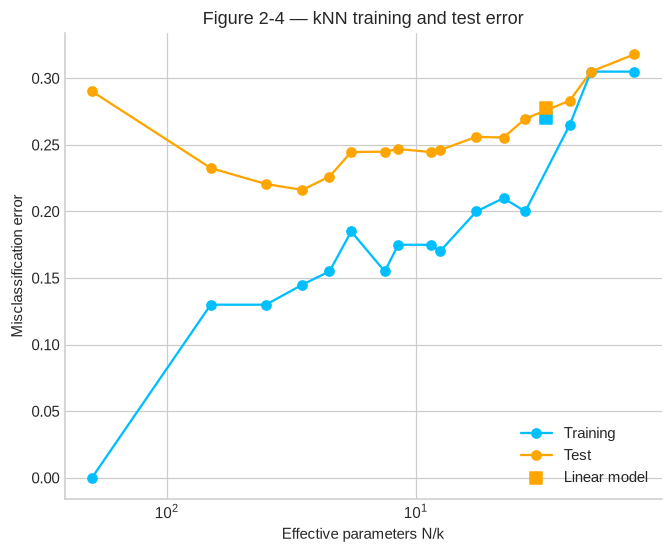

In [6]:
rng_test = np.random.default_rng(1986)

def sample_mixture(n_per_class, rng):
    labels = np.repeat([0, 1], n_per_class)
    center_ids = np.r_[rng.integers(0, 10, n_per_class),
                       rng.integers(10, 20, n_per_class)]
    points = mixture_means[center_ids] + rng.normal(
        0, np.sqrt(.2), size=(2 * n_per_class, 2))
    return points, labels

X_test, y_test = sample_mixture(5_000, rng_test)
k_values = np.array([1, 3, 5, 7, 9, 11, 15, 17, 23, 25, 35, 45,
                     55, 83, 101, 151])
train_error, test_error = [], []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=int(k)).fit(X_train, y_train)
    train_error.append(np.mean(model.predict(X_train) != y_train))
    test_error.append(np.mean(model.predict(X_test) != y_test))

linear_train_error = np.mean((linear_classifier.predict(X_train) > .5) != y_train)
linear_test_error = np.mean((linear_classifier.predict(X_test) > .5) != y_test)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(200 / k_values, train_error, "o-", color=BLUE, label="Training")
ax.plot(200 / k_values, test_error, "o-", color=ORANGE, label="Test")
ax.scatter([3], [linear_train_error], marker="s", s=55, color=BLUE)
ax.scatter([3], [linear_test_error], marker="s", s=55, color=ORANGE,
           label="Linear model")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(xlabel="Effective parameters N/k", ylabel="Misclassification error",
       title="Figure 2-4 — kNN training and test error")
ax.legend(frameon=False)
plt.show()


## Figure 2-5 — Optimal Bayes decision boundary

This figure was a TODO in the R notebook. Because the generating mixture is
known, its Bayes posterior can be evaluated directly. Equal class priors and
equal component weights make the boundary the set where the two class mixture
densities agree.


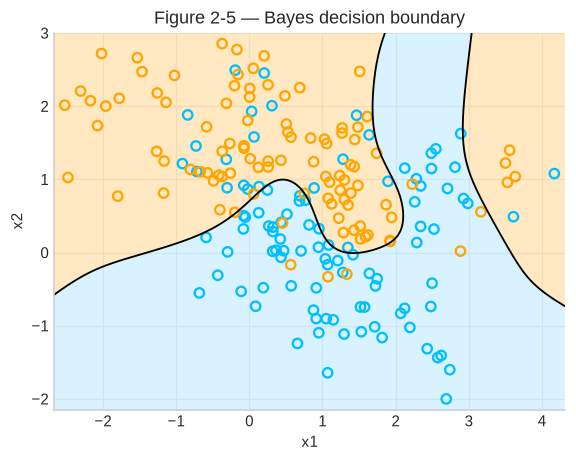

Monte Carlo Bayes error: 0.201


In [7]:
def bayes_probability(points):
    # Common Gaussian constants cancel in the posterior odds.
    sq_dist = ((points[:, None, :] - mixture_means[None, :, :]) ** 2).sum(axis=2)
    log_components = -sq_dist / (2 * .2)
    log_p0 = logsumexp(log_components[:, :10], axis=1)
    log_p1 = logsumexp(log_components[:, 10:], axis=1)
    return 1 / (1 + np.exp(log_p0 - log_p1))

class BayesClassifier:
    def predict(self, points):
        return (bayes_probability(points) > .5).astype(int)

classification_plot(BayesClassifier(), X_train, y_train,
                    "Figure 2-5 — Bayes decision boundary",
                    boundary=bayes_probability)
bayes_error = np.mean((bayes_probability(X_test) > .5) != y_test)
print(f"Monte Carlo Bayes error: {bayes_error:.3f}")


## Figure 2-6 — Curse of dimensionality

A fraction $r$ of the volume of a unit $p$-dimensional cube has side-length
fraction $r^{1/p}$. A local neighborhood therefore becomes very wide as the
dimension increases.


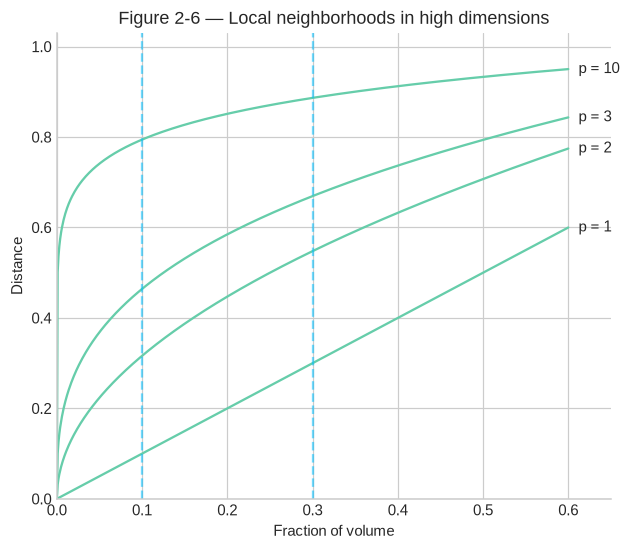

In [8]:
r = np.linspace(0, .6, 601)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for p in [1, 2, 3, 10]:
    distance = r ** (1 / p)
    ax.plot(r, distance, color=GREEN)
    ax.text(r[-1] + .012, distance[-1], f"p = {p}", va="center")
for fraction in [.1, .3]:
    ax.axvline(fraction, ls="--", color=BLUE, alpha=.55)
ax.set(xlim=(0, .65), ylim=(0, 1.03), xlabel="Fraction of volume",
       ylabel="Distance", title="Figure 2-6 — Local neighborhoods in high dimensions")
plt.show()


## Figure 2-7 — Local methods in high dimensions

The target is $f(x)=\exp(-8\lVert xVert^2)$. The lower panels estimate the
nearest-neighbor distance distribution and the 1-NN bias–variance decomposition
at the origin as the dimension grows.


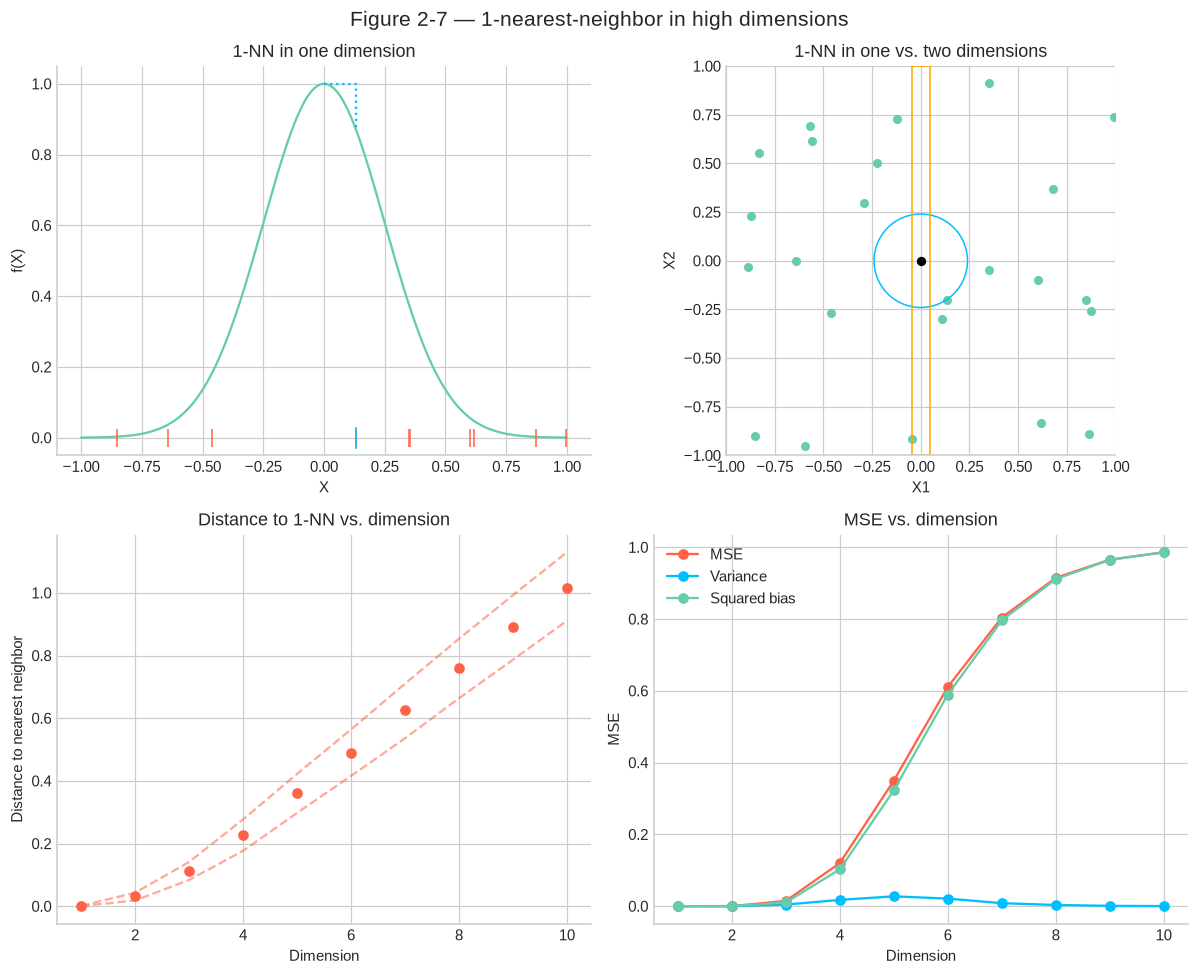

In [9]:
def simulate_uniform(n=1_000, p=10, rng=None):
    return rng.uniform(-1, 1, size=(n, p))

def radial_target(x):
    x = np.asarray(x)
    return np.exp(-8 * np.sum(x * x, axis=-1))

rng_27 = np.random.default_rng(234)
X_high = simulate_uniform(rng=rng_27)
x_1d = X_high[:10, 0]
nearest_1d = x_1d[np.argmin(np.abs(x_1d))]
points_2d = X_high[:24, :2]
nearest_radius = np.sqrt(np.sum(points_2d ** 2, axis=1)).min()
nearest_1d_radius = np.abs(points_2d[:, 0]).min()

dimensions = np.arange(1, 11)
avg_distance, q1_distance, q3_distance = [], [], []
for d in dimensions:
    nn = NearestNeighbors(n_neighbors=2).fit(X_high[:, :d])
    distances, _ = nn.kneighbors(X_high[:, :d])
    nearest = distances[:, 1]
    avg_distance.append(nearest.mean())
    q1_distance.append(np.quantile(nearest, .25))
    q3_distance.append(np.quantile(nearest, .75))

B = 500
predictions = np.empty((B, 10))
rng_mc = np.random.default_rng(27)
for b in range(B):
    sample = simulate_uniform(rng=rng_mc)
    squared_radius = np.cumsum(sample ** 2, axis=1)
    nearest_rows = np.argmin(squared_radius, axis=0)
    predictions[b] = np.exp(-8 * squared_radius[nearest_rows, np.arange(10)])
bias = predictions.mean(axis=0) - 1
variance = predictions.var(axis=0, ddof=1)
squared_bias = bias ** 2
mse = variance + squared_bias

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
grid = np.linspace(-1, 1, 301)
axes[0, 0].plot(grid, np.exp(-8 * grid ** 2), color=GREEN)
axes[0, 0].plot(x_1d, np.zeros_like(x_1d), "|", ms=12, color=RED)
axes[0, 0].plot(nearest_1d, 0, "|", ms=14, color=BLUE)
axes[0, 0].plot([0, nearest_1d, nearest_1d],
                [1, 1, np.exp(-8 * nearest_1d ** 2)], ":", color=BLUE)
axes[0, 0].set(title="1-NN in one dimension", xlabel="X", ylabel="f(X)")

axes[0, 1].scatter(*points_2d.T, color=GREEN, s=24)
axes[0, 1].scatter([0], [0], color="black", s=26)
axes[0, 1].add_patch(Circle((0, 0), nearest_radius, fill=False, color=BLUE))
axes[0, 1].add_patch(Rectangle((-nearest_1d_radius, -1), 2 * nearest_1d_radius, 2,
                               fill=False, color=ORANGE))
axes[0, 1].set(xlim=(-1, 1), ylim=(-1, 1), title="1-NN in one vs. two dimensions",
               xlabel="X1", ylabel="X2", aspect="equal")

axes[1, 0].plot(dimensions, avg_distance, "o", color=RED)
axes[1, 0].plot(dimensions, q1_distance, "--", color=RED, alpha=.55)
axes[1, 0].plot(dimensions, q3_distance, "--", color=RED, alpha=.55)
axes[1, 0].set(title="Distance to 1-NN vs. dimension", xlabel="Dimension",
               ylabel="Distance to nearest neighbor", xticks=dimensions[1::2])

axes[1, 1].plot(dimensions, mse, "o-", color=RED, label="MSE")
axes[1, 1].plot(dimensions, variance, "o-", color=BLUE, label="Variance")
axes[1, 1].plot(dimensions, squared_bias, "o-", color=GREEN, label="Squared bias")
axes[1, 1].set(title="MSE vs. dimension", xlabel="Dimension", ylabel="MSE",
               xticks=dimensions[1::2])
axes[1, 1].legend(frameon=False)
fig.suptitle("Figure 2-7 — 1-nearest-neighbor in high dimensions", fontsize=14)
fig.tight_layout()
plt.show()


## Figure 2-8 — A target that varies in one dimension

Now $f(x)=	frac12(x_1+1)^3$. Extra coordinates do not affect the target but do
affect which observation is considered nearest, increasing variance and bias.


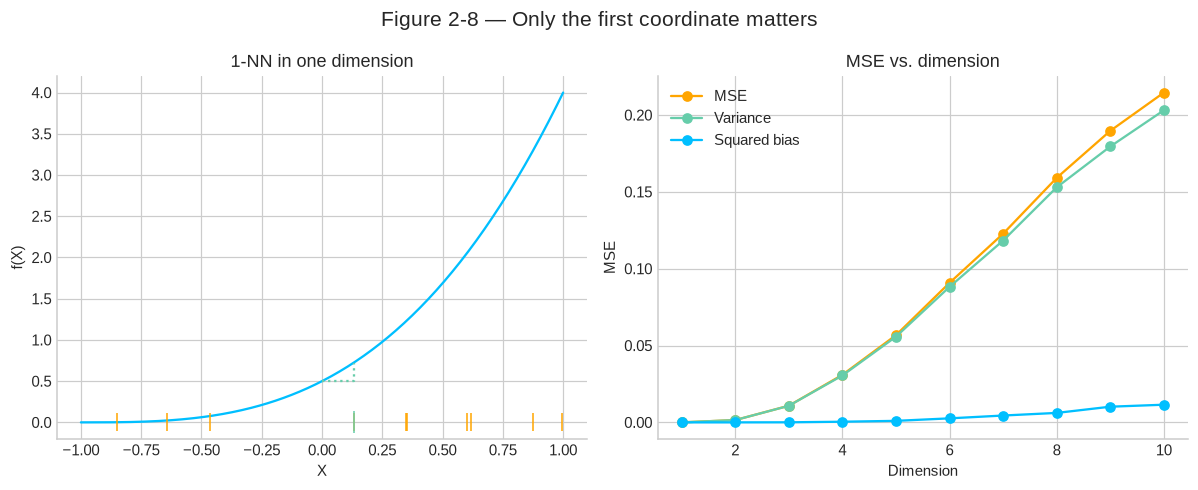

In [10]:
def cubic_target(x1):
    return .5 * (np.asarray(x1) + 1) ** 3

B = 5_000
predictions = np.empty((B, 10))
rng_mc = np.random.default_rng(28)
for b in range(B):
    sample = simulate_uniform(rng=rng_mc)
    squared_radius = np.cumsum(sample ** 2, axis=1)
    nearest_rows = np.argmin(squared_radius, axis=0)
    predictions[b] = cubic_target(sample[nearest_rows, 0])
bias = predictions.mean(axis=0) - .5
variance = predictions.var(axis=0, ddof=1)
squared_bias = bias ** 2
mse = variance + squared_bias

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(grid, cubic_target(grid), color=BLUE)
axes[0].plot(x_1d, np.zeros_like(x_1d), "|", ms=12, color=ORANGE)
axes[0].plot(nearest_1d, 0, "|", ms=14, color=GREEN)
axes[0].plot([0, nearest_1d, nearest_1d],
             [.5, .5, cubic_target(nearest_1d)], ":", color=GREEN)
axes[0].set(title="1-NN in one dimension", xlabel="X", ylabel="f(X)")
axes[1].plot(dimensions, mse, "o-", color=ORANGE, label="MSE")
axes[1].plot(dimensions, variance, "o-", color=GREEN, label="Variance")
axes[1].plot(dimensions, squared_bias, "o-", color=BLUE, label="Squared bias")
axes[1].set(title="MSE vs. dimension", xlabel="Dimension", ylabel="MSE",
            xticks=dimensions[1::2])
axes[1].legend(frameon=False)
fig.suptitle("Figure 2-8 — Only the first coordinate matters", fontsize=14)
fig.tight_layout()
plt.show()


## Figure 2-9 — Expected prediction error: 1-NN versus least squares

The old R chunk divided estimated biases, which is unstable (the linear-model
bias is near zero) and is not an EPE ratio. Here the numerator is the expected
squared prediction error of 1-NN at the origin and the denominator is the same
quantity for least squares. Both include irreducible test noise.


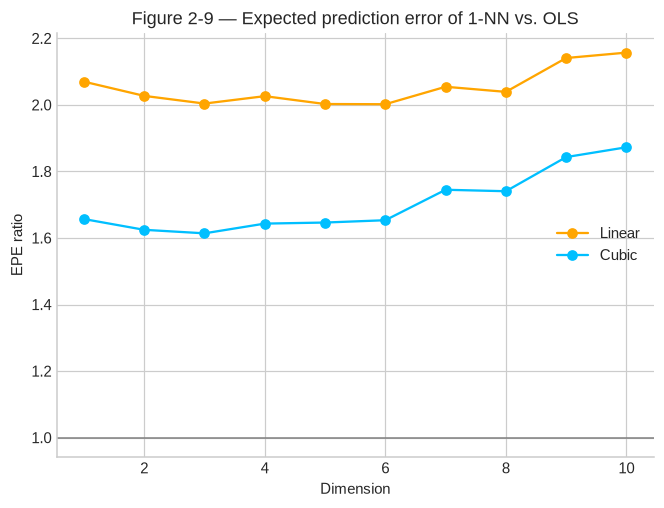

In [11]:
def epe_ratio(target, target_at_zero, B=1_500, n=500, noise_sd=1):
    rng = np.random.default_rng(29)
    nn_predictions = np.empty((B, 10))
    ls_predictions = np.empty(B)
    for b in range(B):
        sample = simulate_uniform(n=n, rng=rng)
        response = target(sample[:, 0]) + rng.normal(0, noise_sd, n)
        design = np.c_[np.ones(n), sample[:, 0]]
        beta, *_ = np.linalg.lstsq(design, response, rcond=None)
        ls_predictions[b] = beta[0]
        squared_radius = np.cumsum(sample ** 2, axis=1)
        nearest_rows = np.argmin(squared_radius, axis=0)
        nn_predictions[b] = response[nearest_rows]
    nn_epe = ((nn_predictions - target_at_zero) ** 2).mean(axis=0) + noise_sd ** 2
    ls_epe = ((ls_predictions - target_at_zero) ** 2).mean() + noise_sd ** 2
    return nn_epe / ls_epe

linear_ratio = epe_ratio(lambda x: x, 0)
cubic_ratio = epe_ratio(cubic_target, .5)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dimensions, linear_ratio, "o-", color=ORANGE, label="Linear")
ax.plot(dimensions, cubic_ratio, "o-", color=BLUE, label="Cubic")
ax.axhline(1, color="gray", lw=1)
ax.set(title="Figure 2-9 — Expected prediction error of 1-NN vs. OLS",
       xlabel="Dimension", ylabel="EPE ratio", xticks=dimensions[1::2])
ax.legend(frameon=False)
plt.show()


## Figure 2-10 — Bias–variance tradeoff

The original R analysis did not include Figure 2-10. This empirical version
decomposes prediction error for polynomial regression into variance, squared
bias, and irreducible error, averaged over the input grid and repeated samples.


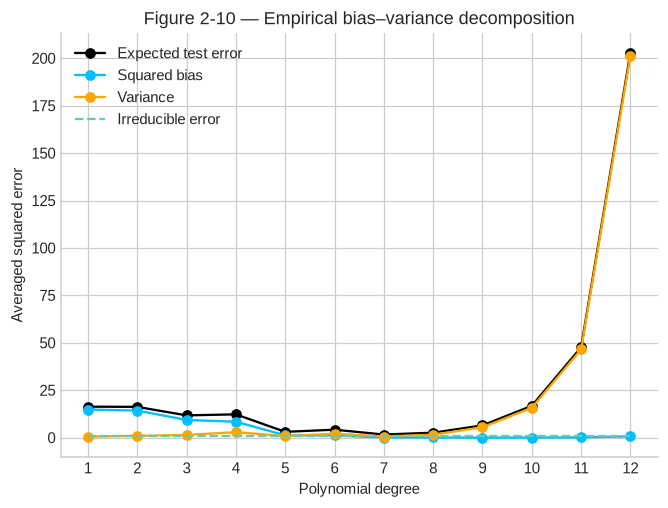

In [12]:
def target_function(x):
    return 5 * np.sin(2 * x) + 2 * np.cos(x + 1)

rng_poly = np.random.default_rng(210)
degrees = np.arange(1, 13)
x_grid = np.linspace(0, 6, 121)
truth_grid = target_function(x_grid)
B = 300
predictions = np.empty((B, len(degrees), len(x_grid)))
for b in range(B):
    x_sample = rng_poly.uniform(0, 6, 50)
    y_sample = target_function(x_sample) + rng_poly.normal(size=50)
    for j, degree in enumerate(degrees):
        coefficients = np.polynomial.Polynomial.fit(x_sample, y_sample, degree)
        predictions[b, j] = coefficients(x_grid)

mean_prediction = predictions.mean(axis=0)
variance = predictions.var(axis=0).mean(axis=1)
squared_bias = ((mean_prediction - truth_grid) ** 2).mean(axis=1)
irreducible_error = np.ones_like(degrees)
expected_test_error = variance + squared_bias + irreducible_error

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(degrees, expected_test_error, "o-", label="Expected test error", color="black")
ax.plot(degrees, squared_bias, "o-", label="Squared bias", color=BLUE)
ax.plot(degrees, variance, "o-", label="Variance", color=ORANGE)
ax.plot(degrees, irreducible_error, "--", label="Irreducible error", color=GREEN)
ax.set(title="Figure 2-10 — Empirical bias–variance decomposition",
       xlabel="Polynomial degree", ylabel="Averaged squared error", xticks=degrees)
ax.legend(frameon=False)
plt.show()


## Figure 2-11 — Model selection and the bias–variance tradeoff

As in the R notebook, repeated train/test samples show the typical U-shaped
test error and monotonically decreasing training error as polynomial degree
increases.


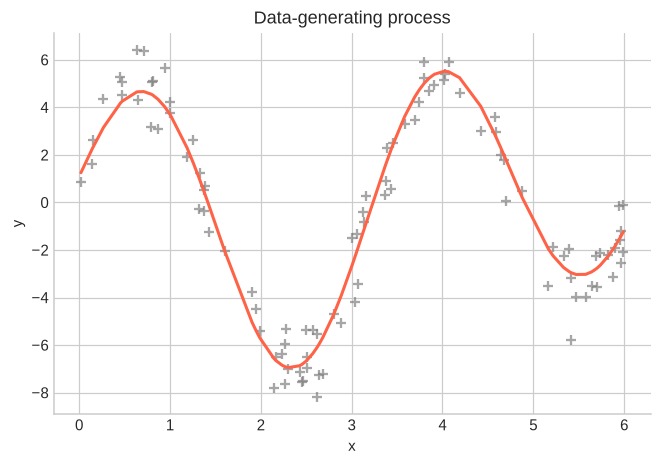

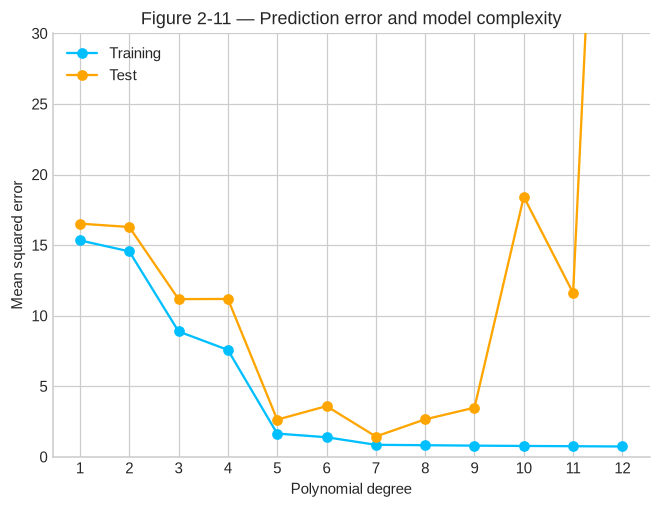

In [13]:
rng_dgp = np.random.default_rng(211)
x_observed = rng_dgp.uniform(0, 6, 100)
y_observed = target_function(x_observed) + rng_dgp.normal(size=100)
order = np.argsort(x_observed)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_observed, y_observed, marker="+", color="gray", alpha=.7)
ax.plot(x_observed[order], target_function(x_observed[order]), color=RED, lw=2)
ax.set(title="Data-generating process", xlabel="x", ylabel="y")
plt.show()

B = 500
train_errors = np.empty((B, len(degrees)))
test_errors = np.empty_like(train_errors)
last_train = None
for b in range(B):
    x = rng_dgp.uniform(0, 6, 100)
    y = target_function(x) + rng_dgp.normal(size=100)
    x_train, x_holdout = x[:50], x[50:]
    y_train_poly, y_holdout = y[:50], y[50:]
    for j, degree in enumerate(degrees):
        model = np.polynomial.Polynomial.fit(x_train, y_train_poly, degree)
        train_errors[b, j] = np.mean((y_train_poly - model(x_train)) ** 2)
        test_errors[b, j] = np.mean((y_holdout - model(x_holdout)) ** 2)
    last_train = (x_train, y_train_poly)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(degrees, train_errors.mean(axis=0), "o-", label="Training", color=BLUE)
ax.plot(degrees, test_errors.mean(axis=0), "o-", label="Test", color=ORANGE)
ax.set(title="Figure 2-11 — Prediction error and model complexity",
       xlabel="Polynomial degree", ylabel="Mean squared error", xticks=degrees,
       ylim=(0, 30))
ax.legend(frameon=False)
plt.show()


### Comparing underfit, reasonable, and overfit polynomial models

This companion panel follows the additional comparison in the R notebook.


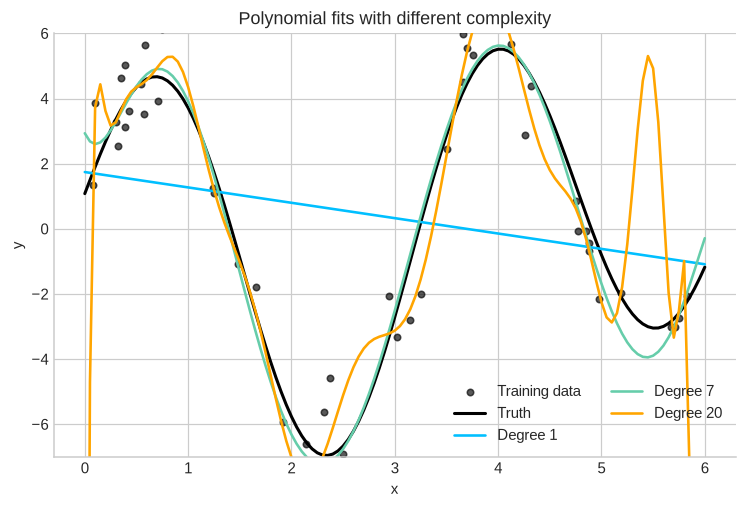

In [14]:
x_train, y_train_poly = last_train
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_train, y_train_poly, color="black", s=18, alpha=.65, label="Training data")
ax.plot(x_grid, truth_grid, lw=2, color="black", label="Truth")
for degree, color in [(1, BLUE), (7, GREEN), (20, ORANGE)]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = np.polynomial.Polynomial.fit(x_train, y_train_poly, degree)
    ax.plot(x_grid, model(x_grid), lw=1.7, color=color, label=f"Degree {degree}")
ax.set(xlabel="x", ylabel="y", ylim=(-7, 6),
       title="Polynomial fits with different complexity")
ax.legend(frameon=False, ncol=2)
plt.show()


## Bonus classifiers from the original R notebook

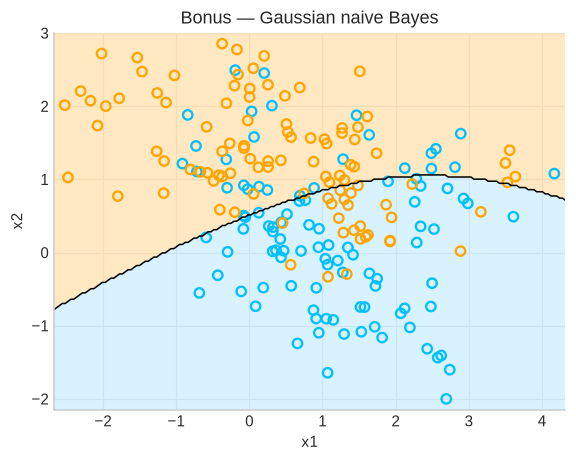

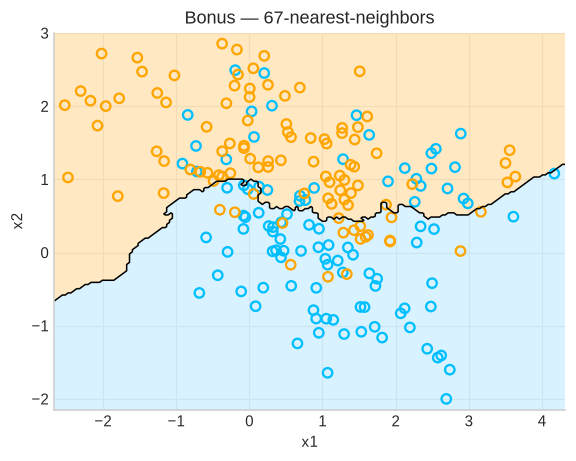

In [15]:
naive_bayes = GaussianNB().fit(X_train, y_train)
classification_plot(naive_bayes, X_train, y_train, "Bonus — Gaussian naive Bayes")

knn67 = KNeighborsClassifier(n_neighbors=67).fit(X_train, y_train)
classification_plot(knn67, X_train, y_train, "Bonus — 67-nearest-neighbors")


## Notes

- Figures 2-1 to 2-9 and 2-11 are Python ports of the corresponding R sections.
- Figure 2-5 completes the Bayes-boundary TODO from the R notebook.
- Figure 2-9 uses prediction errors rather than the erroneous ratio of biases.
- Figure 2-10 is an empirical addition because the R notebook skipped it.
